## EDA by Swosti

### dataset loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

dataset = pd.read_csv(f"{path}/WA_Fn-UseC_-Telco-Customer-Churn.csv")

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [3]:
dataset.to_csv("Telco-Customer-Churn.csv",index=False)

### dataset analysis

In [ ]:
dataset.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
dataset.shape

(7043, 21)

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**as we can see most of the data are object type so we have to process it !!**

In [ ]:
dataset.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
# Checking Missing values
dataset.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
# checking duplicates
dataset.duplicated().sum()

np.int64(0)

*we see that no duplicate and null values are present!!*

In [ ]:
# Unique values
for col in dataset.columns:
    print(col,"-", dataset[col].nunique())

customerID - 7043
gender - 2
SeniorCitizen - 2
Partner - 2
Dependents - 2
tenure - 73
PhoneService - 2
MultipleLines - 3
InternetService - 3
OnlineSecurity - 3
OnlineBackup - 3
DeviceProtection - 3
TechSupport - 3
StreamingTV - 3
StreamingMovies - 3
Contract - 3
PaperlessBilling - 2
PaymentMethod - 4
MonthlyCharges - 1585
TotalCharges - 6531
Churn - 2


we see that besides columns like **tenure, MonthlyCharges, and TotalCharges** everything can be encoded as categories.

### Graphical Analysis

**UNIVARIATE ANALYSIS**

In [ ]:
dataset.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [ ]:
# donot take CustomerID as it is unique primary key
cat_cols = [ 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']

In [ ]:
dataset['TotalCharges'].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

In [ ]:
# as TotalCharges is in object datatype we convert it into numeric
# This forces conversion and turns ' ' into NaN
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
# this creates some null values in TotalCharges

**NUMERICAL COLUMNS**

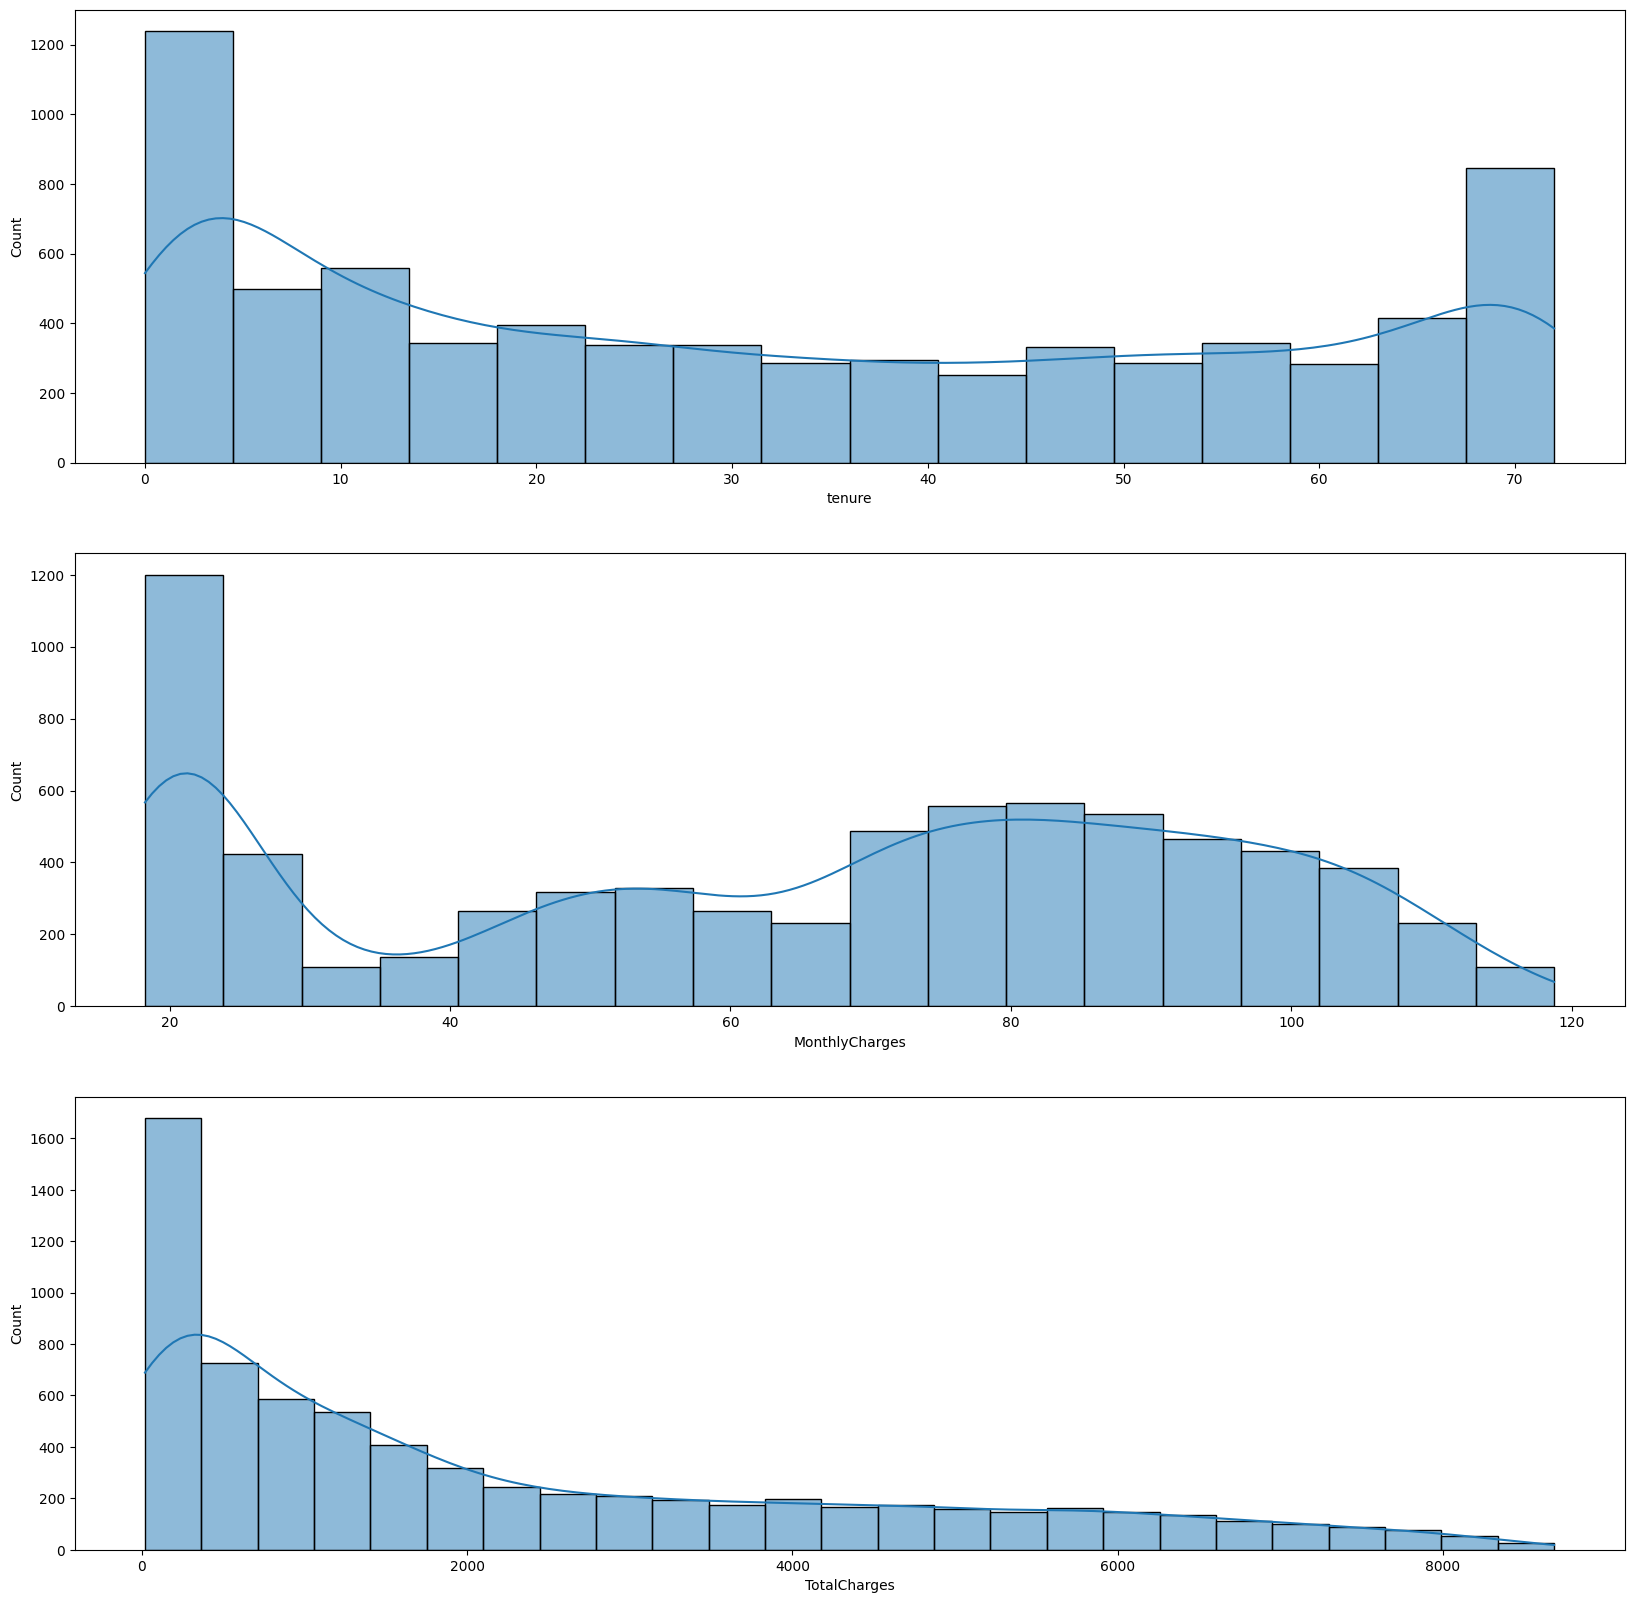

In [ ]:
plt.figure(figsize=(20, 20))

for i in range(0,len(num_cols)):
  plt.subplot(3,1,i+1) #(3,1,i+1) means 3 rows 1 column and i+1 is the position of the graph 1 to n
  sns.histplot(dataset[num_cols[i]], kde=True)

plt.show()

In [ ]:
# Skewness
for col in num_cols:
  print(col," = ",dataset[col].skew())

tenure  =  0.2395397495619829
MonthlyCharges  =  -0.22052443394398033
TotalCharges  =  0.961642499724251


**SKEWNESS**

0 - Symmetric

\>1 - highly right skewed

<-1 - highly left skewed

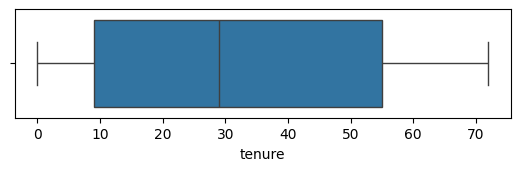

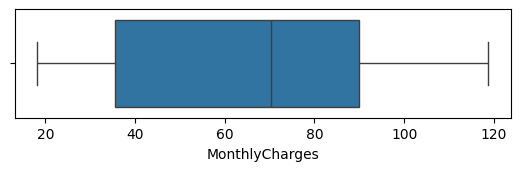

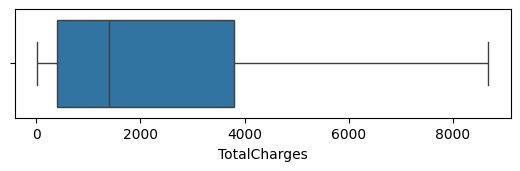

In [ ]:
# BoxPlots
for i in range(0,len(num_cols)):
   plt.subplot(3,1,i+1)
   sns.boxplot(x=dataset[num_cols[i]])
   plt.show()

we see no visible outliers here in these numerical columns

In [ ]:
# Outliers Count !!
for i in range(0,len(num_cols)):
  Q1 = dataset[num_cols[i]].quantile(0.25)
  Q3 = dataset[num_cols[i]].quantile(0.75)

  IQR = Q3-Q1

  lower = Q1 - 1.5*IQR
  upper = Q3 + 1.5*IQR

  outliers = dataset[(dataset[num_cols[i]] < lower) | (dataset[num_cols[i]] > upper)]

  print(num_cols[i], len(outliers))

tenure 0
MonthlyCharges 0
TotalCharges 0


**CATEGORICAL COLUMNS**

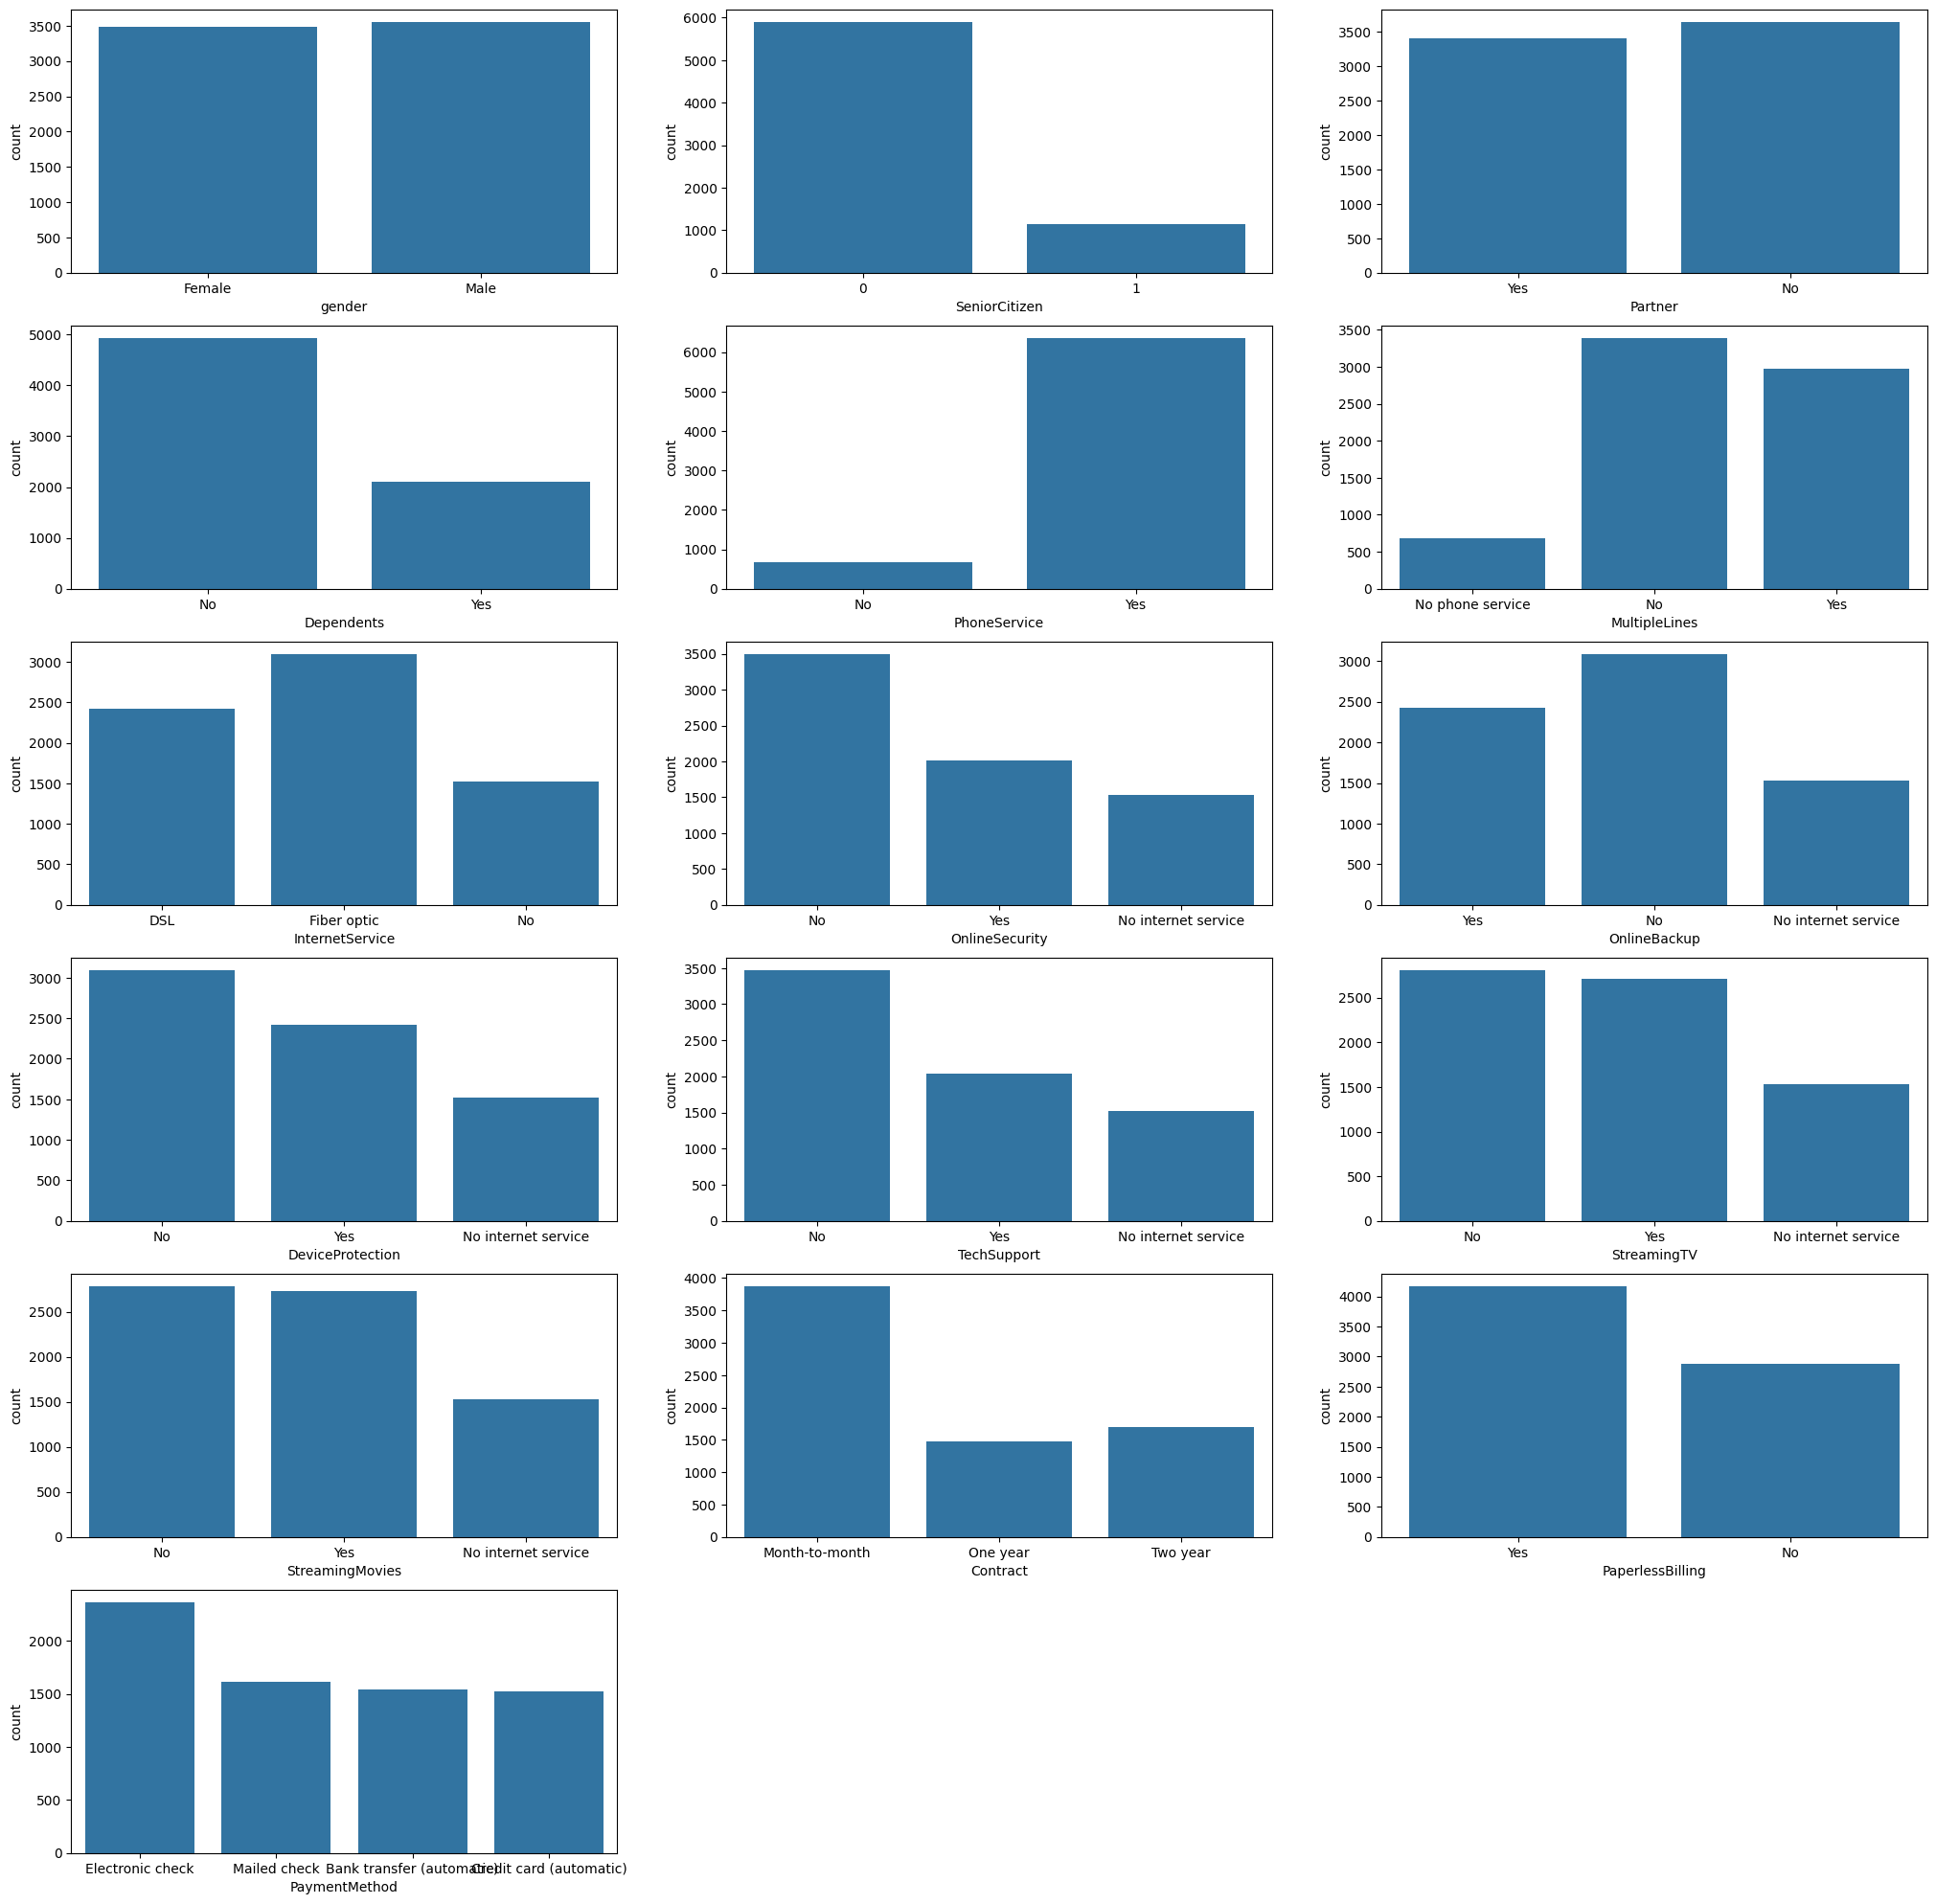

In [ ]:
# Count Plots
plt.figure(figsize=(25, 25))

for i in range(0,len(cat_cols)):
  plt.subplot(6,3,i+1)
  sns.countplot(x = cat_cols[i], data=dataset)

plt.show()

In [ ]:
# Percentage Distribution
for i in range(0,len(cat_cols)):
  print(dataset[cat_cols[i]].value_counts(normalize=True)*100)
  print()

gender
Male      50.47565
Female    49.52435
Name: proportion, dtype: float64

SeniorCitizen
0    83.785319
1    16.214681
Name: proportion, dtype: float64

Partner
No     51.69672
Yes    48.30328
Name: proportion, dtype: float64

Dependents
No     70.041176
Yes    29.958824
Name: proportion, dtype: float64

PhoneService
Yes    90.316626
No      9.683374
Name: proportion, dtype: float64

MultipleLines
No                  48.132898
Yes                 42.183729
No phone service     9.683374
Name: proportion, dtype: float64

InternetService
Fiber optic    43.958540
DSL            34.374556
No             21.666903
Name: proportion, dtype: float64

OnlineSecurity
No                     49.666335
Yes                    28.666761
No internet service    21.666903
Name: proportion, dtype: float64

OnlineBackup
No                     43.844952
Yes                    34.488144
No internet service    21.666903
Name: proportion, dtype: float64

DeviceProtection
No                     43.944342
Ye

**MULTI-VARIATE ANALYSIS**

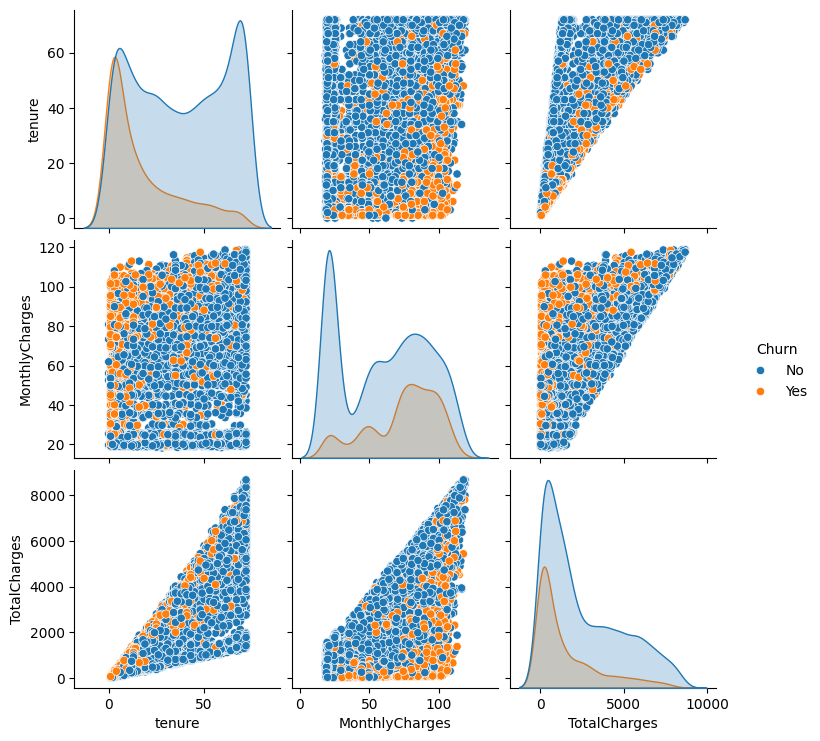

In [ ]:
sns.pairplot(dataset[num_cols + ['Churn']], hue="Churn")
# hue can be added for a particular categorical feature..

<Axes: >

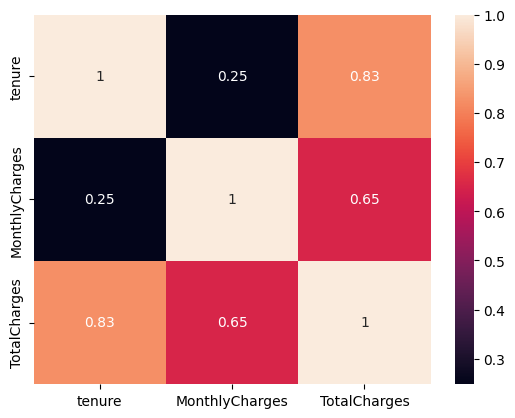

In [ ]:
sns.heatmap(dataset[num_cols].corr(),annot=True)

*As we can see nothing can be discarded as nothing is highly correlated..*

**CATEGORICAL CORRELATION USING CHI SQUARE AND CRAMER'S V???**

In [ ]:
from scipy.stats import chi2_contingency

def batch_chi_square_test(df, categorical_features, target_col):
    results = []

    # Ensure the target column isn't accidentally tested against itself
    features_to_test = [col for col in categorical_features if col != target_col]

    for col in features_to_test:
        # 1. Create the raw contingency table (cross-tabulation)
        contingency_table = pd.crosstab(df[col], df[target_col])

        # 2. Execute the Chi-Square Test
        chi2, p_val, dof, expected = chi2_contingency(contingency_table)

        # 3. Calculate Cramér's V for relationship strength
        total_obs = contingency_table.sum().sum()
        min_dim = min(contingency_table.shape) - 1

        # Handle edge case where a feature has only 1 unique value to prevent division by zero
        if min_dim == 0:
            cramers_v = 0.0
        else:
            cramers_v = np.sqrt(chi2 / (total_obs * min_dim))

        # 4. Define feature selection action based on standard alpha = 0.05
        action = "KEEP" if p_val < 0.05 else "DROP (Independent)"

        # Store results in a dictionary
        results.append({
            'Feature': col,
            'Chi-Square Stat': round(chi2, 2),
            'P-Value': p_val, # Kept raw to see scientific notation if extremely small
            'Cramér\'s V': round(cramers_v, 4),
            'Recommendation': action
        })

    # Convert list of results to a structured DataFrame
    results_df = pd.DataFrame(results)

    # Sort by Cramér's V descending so the strongest predictors bubble to the top
    return results_df.sort_values(by='Cramér\'s V', ascending=False).reset_index(drop=True)

summary_report = batch_chi_square_test(dataset, cat_cols, target_col='Churn')
print(summary_report)

             Feature  Chi-Square Stat        P-Value  Cramér's V  \
0           Contract          1184.60  5.863038e-258      0.4101   
1     OnlineSecurity           850.00  2.661150e-185      0.3474   
2        TechSupport           828.20  1.443084e-180      0.3429   
3    InternetService           732.31  9.571788e-160      0.3225   
4      PaymentMethod           648.14  3.682355e-140      0.3034   
5       OnlineBackup           601.81  2.079759e-131      0.2923   
6   DeviceProtection           558.42  5.505219e-122      0.2816   
7    StreamingMovies           375.66   2.667757e-82      0.2310   
8        StreamingTV           374.20   5.528994e-82      0.2305   
9   PaperlessBilling           258.28   4.073355e-58      0.1915   
10        Dependents           189.13   4.924922e-43      0.1639   
11     SeniorCitizen           159.43   1.510067e-36      0.1505   
12           Partner           158.73   2.139911e-36      0.1501   
13     MultipleLines            11.33   3.464383

*I can see that gender and Phone service both should be dropped according to chisquare test, but seeing the cramers value we can say that gender is much less important.. so drop that...*

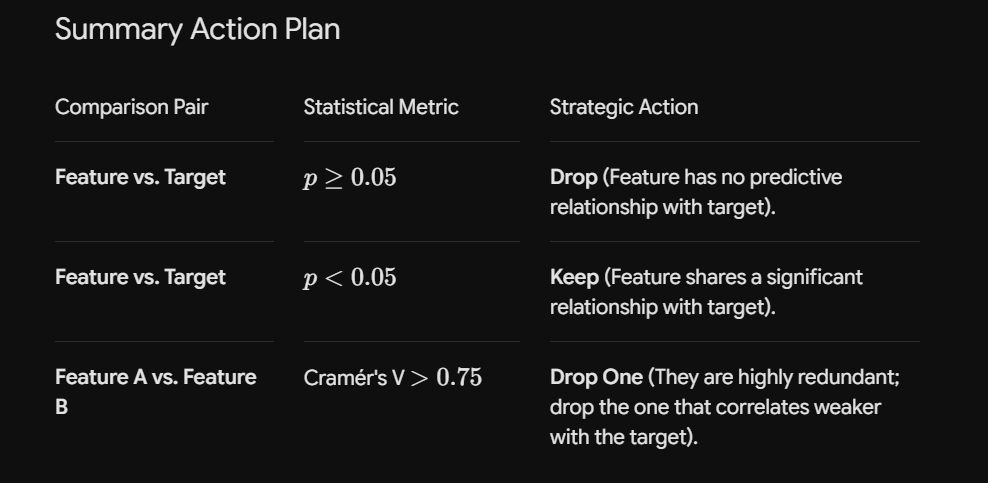

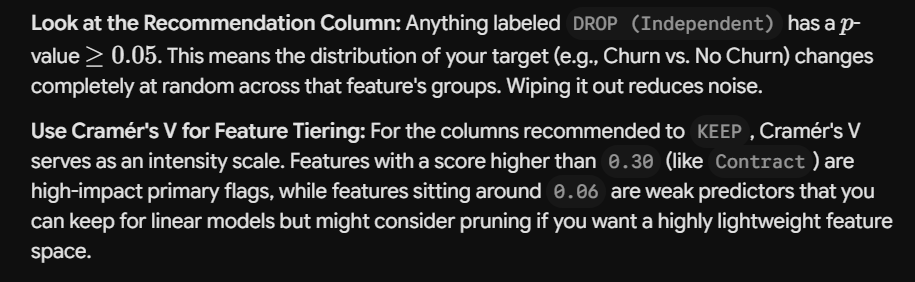

**TARGET ANALYSIS**

In [ ]:
dataset['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


*We see that there is a huge imbalance in the output data* -> use **SMOTE**

### DATA CLEANING

In [ ]:
df_clean = dataset.copy()

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
for i in df_clean.columns:
  print(i)
  print(df_clean[i].unique()," => " ,df_clean[i].nunique())
  print()

customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']  =>  7043

gender
['Female' 'Male']  =>  2

SeniorCitizen
[0 1]  =>  2

Partner
['Yes' 'No']  =>  2

Dependents
['No' 'Yes']  =>  2

tenure
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]  =>  73

PhoneService
['No' 'Yes']  =>  2

MultipleLines
['No phone service' 'No' 'Yes']  =>  3

InternetService
['DSL' 'Fiber optic' 'No']  =>  3

OnlineSecurity
['No' 'Yes' 'No internet service']  =>  3

OnlineBackup
['Yes' 'No' 'No internet service']  =>  3

DeviceProtection
['No' 'Yes' 'No internet service']  =>  3

TechSupport
['No' 'Yes' 'No internet service']  =>  3

StreamingTV
['No' 'Yes' 'No internet service']  =>  3

StreamingMovies
['No' 'Yes' 'No internet service']  =>  3

Contract
['Month-to-month' 'One year' 'Two year']

**we can remove the CustomerID column as it is totally unique and is different for each record**

In [ ]:
df_clean.drop(columns='customerID', inplace=True)

In [ ]:
df_clean.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df_clean.dropna(subset=['TotalCharges'],inplace=True)

In [ ]:
df_clean.duplicated().sum()

np.int64(22)

In [ ]:
df_clean.drop_duplicates(inplace=True)

In [ ]:
df_clean.shape

(7010, 20)

**No Outliers are present as we have seen earlier.. so it is skipped here**

In [ ]:
# Remove Gende and PhoneService as it is a very weak predictor...
df_clean.drop(columns=["gender","PhoneService"], inplace=True)

### FEATURE ENGINEERING & DATA PREPROCESSING

In [ ]:
df_clean.head()

,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Yes,No,1,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,0,No,No,34,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,0,No,No,2,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,0,No,No,45,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,No,No,2,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**ENCODING CAT COLS**

In [ ]:
cat_cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [ ]:
#list of columns you actually want to encode
cols_to_encode = [col for col in cat_cols if col not in ['gender', 'PhoneService']]
cols_to_encode.append("Churn")
encoded_df = pd.get_dummies(df_clean[cols_to_encode], drop_first=True).astype(int)

# merge these back into your main clean dataframe:
df_clean = pd.concat([df_clean.drop(columns=cols_to_encode), encoded_df], axis=1)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7010 entries, 0 to 7042
Data columns (total 29 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   tenure                                 7010 non-null   int64  
 1   MonthlyCharges                         7010 non-null   float64
 2   TotalCharges                           7010 non-null   float64
 3   SeniorCitizen                          7010 non-null   int64  
 4   Partner_Yes                            7010 non-null   int64  
 5   Dependents_Yes                         7010 non-null   int64  
 6   MultipleLines_No phone service         7010 non-null   int64  
 7   MultipleLines_Yes                      7010 non-null   int64  
 8   InternetService_Fiber optic            7010 non-null   int64  
 9   InternetService_No                     7010 non-null   int64  
 10  OnlineSecurity_No internet service     7010 non-null   int64  
 11  OnlineSec

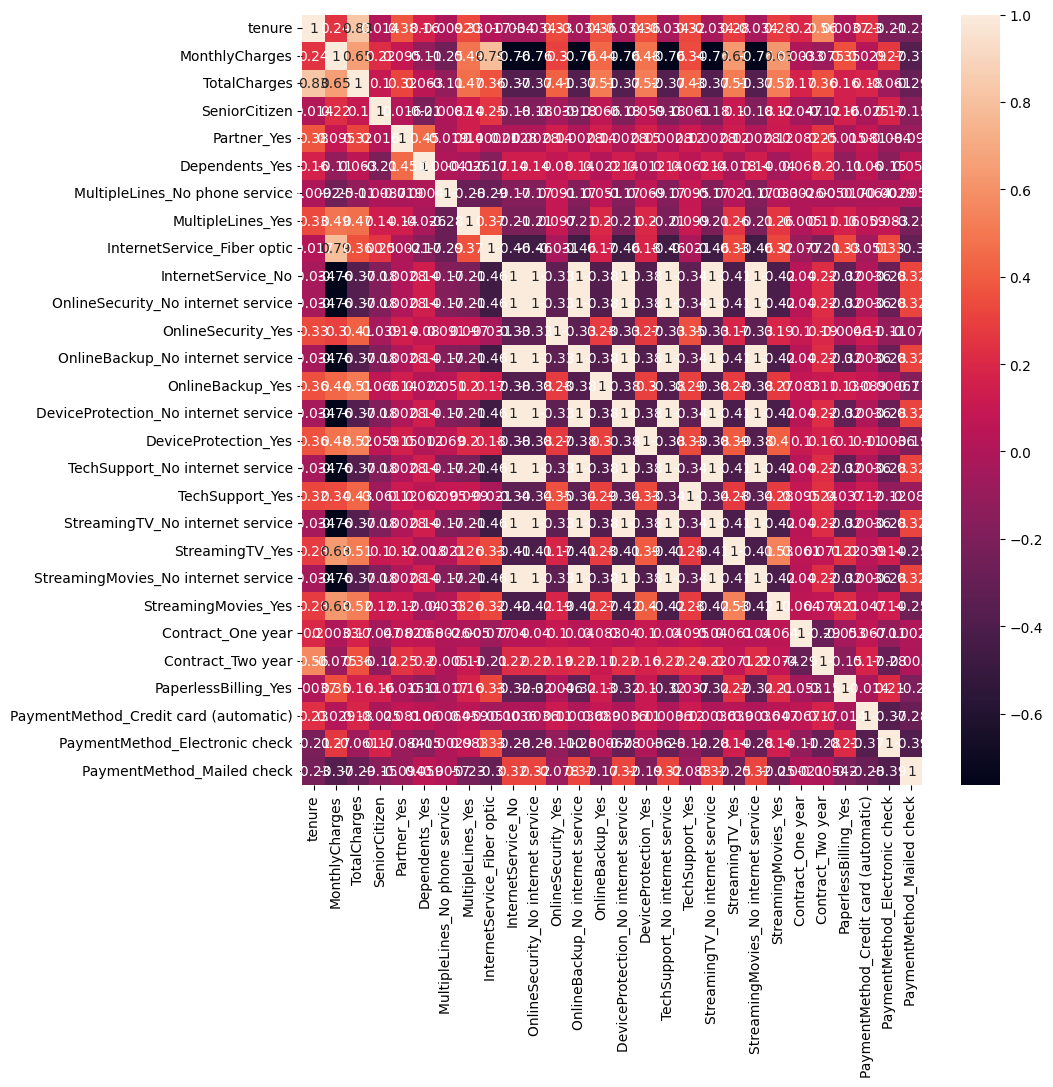

In [ ]:
plt.figure(figsize=(10,10))

sns.heatmap(df_clean.drop(columns="Churn_Yes").corr(), annot=True)

plt.show()

We see that the column InternetService_No is highly correlated with other no internet service columns so we should drop them..

In [ ]:
df_clean.columns

Index(['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen',
       'Partner_Yes', 'Dependents_Yes', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No internet service',
       'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'Churn_Yes'],
      dtype='object')

In [ ]:
cols_to_be_dropped = ['OnlineSecurity_No internet service',
        'OnlineBackup_No internet service',
       'DeviceProtection_No internet service',
        'TechSupport_No internet service',
       'StreamingTV_No internet service',
       'StreamingMovies_No internet service']

In [ ]:
df_clean.drop(columns=cols_to_be_dropped, inplace=True)

In [ ]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

**Scaling Numerical Columns**

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

df_clean[num_cols] = sc.fit_transform(df_clean[num_cols])

In [ ]:
df_clean.head()

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Partner_Yes,Dependents_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,...,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,-1.285566,-1.165523,-0.997284,0,1,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
1,0.060346,-0.264071,-0.176848,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
2,-1.244781,-0.367189,-0.962740,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,1
3,0.508983,-0.751387,-0.198355,0,0,0,1,0,0,0,...,1,0,0,1,0,0,0,0,0,0
4,-1.244781,0.193308,-0.943549,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,1,0,1


In [ ]:
# Skewness
for col in num_cols:
  print(col," = ",df_clean[col].skew())

tenure  =  0.2337404638074156
MonthlyCharges  =  -0.2256859216372037
TotalCharges  =  0.9583220586626406


**Remove Skewness in TotalCharges**

In [ ]:
# Log transformation
df_clean['TotalCharges_log'] = np.log1p(df_clean['TotalCharges'])
print("New Skewness:", df_clean['TotalCharges_log'].skew())

New Skewness: -1.0747093806105097


/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


As we can see logtransformation makes the right skewed TotalCharges to Left skewed so we apply a better transformer...|

In [ ]:
from sklearn.preprocessing import PowerTransformer

'''
The Yeo-Johnson algorithm mathematically scans your specific column and
solves for a custom variance-stabilizing exponent ($lambda$) to
bring your skewness score as close to 0.0 as possible.
'''
pt = PowerTransformer(method='yeo-johnson')

df_clean['TotalCharges_yj'] = pt.fit_transform(df_clean[['TotalCharges']])

print("Yeo-Johnson Skewness:", df_clean['TotalCharges_yj'].skew())

Yeo-Johnson Skewness: 0.2552001617453903


In [ ]:
df_clean.drop(columns = ['TotalCharges_log', 'TotalCharges'], inplace=True)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7010 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   tenure                                 7010 non-null   float64
 1   MonthlyCharges                         7010 non-null   float64
 2   SeniorCitizen                          7010 non-null   int64  
 3   Partner_Yes                            7010 non-null   int64  
 4   Dependents_Yes                         7010 non-null   int64  
 5   MultipleLines_No phone service         7010 non-null   int64  
 6   MultipleLines_Yes                      7010 non-null   int64  
 7   InternetService_Fiber optic            7010 non-null   int64  
 8   InternetService_No                     7010 non-null   int64  
 9   OnlineSecurity_Yes                     7010 non-null   int64  
 10  OnlineBackup_Yes                       7010 non-null   int64  
 11  DevicePro

In [ ]:
df_clean.shape

(7010, 23)

In [ ]:
df_clean.to_csv("cleaned_dataset.csv")

In [ ]:
X = df_clean.drop(columns=['Churn_Yes'])
y = df_clean['Churn_Yes']

### SMOTE

*SMOTE technique works better with Logistic Regression*

*For tree-based models like Random Forest and XGBoost, sometimes class_weight='balanced' performs better than SMOTE*

In [ ]:
(y.value_counts(normalize=True) * 100)

,proportion
Churn_Yes,
0,73.509272
1,26.490728


In [ ]:
from sklearn.model_selection import train_test_split
# Always split before SMOTING!!!! important
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [ ]:
(y_train.value_counts(normalize=True) * 100)

,proportion
Churn_Yes,
0,73.50214
1,26.49786


In [ ]:
(y_train_smote.value_counts(normalize=True) * 100)

,proportion
Churn_Yes,
0,50.0
1,50.0


### Trial Model TESTING

**Without SMOTE**

In [ ]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1031
           1       0.68      0.52      0.59       371

    accuracy                           0.81      1402
   macro avg       0.76      0.72      0.73      1402
weighted avg       0.80      0.81      0.80      1402



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Without SMOTE
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train, y_train)

y_pred_dt = dt_clf.predict(X_test)

print('Decision Tree Classifier (Without SMOTE):')
print(classification_report(
    y_test,
    y_pred_dt
))

Decision Tree Classifier (Without SMOTE):
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1031
           1       0.46      0.47      0.47       371

    accuracy                           0.72      1402
   macro avg       0.64      0.64      0.64      1402
weighted avg       0.72      0.72      0.72      1402



**WITH SMOTE**

In [ ]:
# With SMOTE
dt_clf_smote = DecisionTreeClassifier(random_state=42)
dt_clf_smote.fit(X_train_smote, y_train_smote)

y_pred_dt_smote = dt_clf_smote.predict(X_test)

print('Decision Tree Classifier (With SMOTE):')
print(classification_report(
    y_test,
    y_pred_dt_smote
))

Decision Tree Classifier (With SMOTE):
              precision    recall  f1-score   support

           0       0.84      0.77      0.80      1031
           1       0.48      0.58      0.52       371

    accuracy                           0.72      1402
   macro avg       0.66      0.67      0.66      1402
weighted avg       0.74      0.72      0.73      1402



In [ ]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train_smote, y_train_smote)

y_pred_lr_smote = clf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

accuracy_logistic = accuracy_score(y_test, y_pred_lr_smote)
print(f"Logistic Accuracy: {accuracy_logistic:.4f}")

display(pd.DataFrame(confusion_matrix(y_test, y_pred_lr_smote), index=['Actual Negative', 'Actual Positive'], columns=['Predicted Negative', 'Predicted Positive']))

print(classification_report(
    y_test,
    y_pred_lr_smote
))

Logistic Accuracy: 0.7632


,Predicted Negative,Predicted Positive
Actual Negative,798,233
Actual Positive,99,272


              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1031
           1       0.54      0.73      0.62       371

    accuracy                           0.76      1402
   macro avg       0.71      0.75      0.72      1402
weighted avg       0.80      0.76      0.77      1402



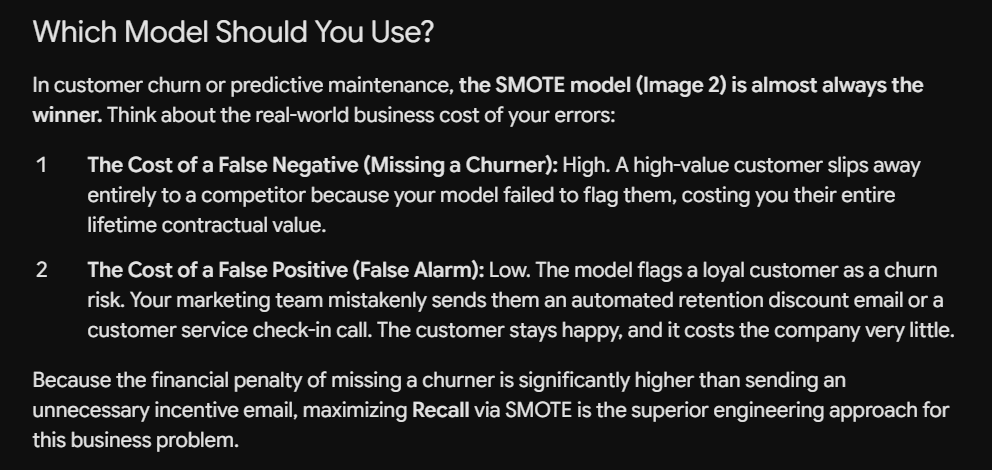

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# train Random Forest Classifier
random_forest_model = RandomForestClassifier(random_state=42)
random_forest_model.fit(X_train, y_train)

y_pred_random_forest = random_forest_model.predict(X_test)

accuracy_random_forest = accuracy_score(y_test, y_pred_random_forest)
print(f"Random Forest Accuracy: {accuracy_random_forest:.4f}")

display(pd.DataFrame(confusion_matrix(y_test, y_pred_random_forest), index=['Actual Negative', 'Actual Positive'], columns=['Predicted Negative', 'Predicted Positive']))

print("\nRF Classification Report:")
print(classification_report(y_test, y_pred_random_forest))

Random Forest Accuracy: 0.7789


,Predicted Negative,Predicted Positive
Actual Negative,925,106
Actual Positive,204,167



RF Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1031
           1       0.61      0.45      0.52       371

    accuracy                           0.78      1402
   macro avg       0.72      0.67      0.69      1402
weighted avg       0.76      0.78      0.77      1402



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# train Random Forest Classifier
random_forest_model = RandomForestClassifier(random_state=42)
random_forest_model.fit(X_train_smote, y_train_smote)


y_pred_random_forest = random_forest_model.predict(X_test)

accuracy_random_forest = accuracy_score(y_test, y_pred_random_forest)
print(f"Random Forest Accuracy: {accuracy_random_forest:.4f}")

display(pd.DataFrame(confusion_matrix(y_test, y_pred_random_forest), index=['Actual Negative', 'Actual Positive'], columns=['Predicted Negative', 'Predicted Positive']))

print("\nRF Classification Report:")
print(classification_report(y_test, y_pred_random_forest))

Random Forest Accuracy: 0.7589


,Predicted Negative,Predicted Positive
Actual Negative,851,180
Actual Positive,158,213



RF Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.83      1031
           1       0.54      0.57      0.56       371

    accuracy                           0.76      1402
   macro avg       0.69      0.70      0.70      1402
weighted avg       0.76      0.76      0.76      1402



###**HyperParameter tuning... on Best Model so far..**

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# 1. Construct an imblearn pipeline
# This guarantees SMOTE is only applied to training folds during cross-validation
pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 2. Update the parameter grid to target the classifier step
# Let's drop 'l1' since it was too aggressive, and stick to stable 'l2' (Ridge)
param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 5.0, 10.0],
    'classifier__penalty': ['l2'],
    'classifier__solver': ['lbfgs', 'saga']
}

# 3. Initialize GridSearch on the raw, un-SMOTEd training data
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1', # Optimizes the binary target class F1-score
    cv=5,
    n_jobs=-1
)

# 4. Pass the ORIGINAL X_train (scaled), NOT the resampled one
grid_search.fit(X_train, y_train)

# 5. Evaluate on the untouched test set
best_pipeline = grid_search.best_estimator_
y_pred_fixed = best_pipeline.predict(X_test)

print("True Best Parameters:", grid_search.best_params_)
print("\n--- Pipeline Tuned Classification Report ---")
print(classification_report(y_test, y_pred_fixed))

True Best Parameters: {'classifier__C': 0.01, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}

--- Pipeline Tuned Classification Report ---
              precision    recall  f1-score   support

           0       0.89      0.77      0.82      1031
           1       0.53      0.73      0.61       371

    accuracy                           0.76      1402
   macro avg       0.71      0.75      0.72      1402
weighted avg       0.79      0.76      0.77      1402



**Optimizing Decision Thresholds**

By default, classification models assign predictions using a fixed 0.5 probability threshold. For imbalanced problems like churn, shifting this threshold allows you to directly control the trade-off between Recall (catching churners) and Precision (reducing false alarms).

In [ ]:
# 1. Get predicted probabilities for Class 1 (Churn) on the test set
y_probs = best_pipeline.predict_proba(X_test)[:, 1]

# 2. Evaluate performance across different probability thresholds
thresholds = [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for thresh in thresholds:
    y_pred_thresh = (y_probs >= thresh).astype(int)
    print(f"\n================ Threshold: {thresh} ================")
    print(classification_report(y_test, y_pred_thresh))


================ Threshold: 0.35 ================
              precision    recall  f1-score   support

           0       0.94      0.62      0.75      1031
           1       0.46      0.89      0.61       371

    accuracy                           0.70      1402
   macro avg       0.70      0.76      0.68      1402
weighted avg       0.81      0.70      0.71      1402


================ Threshold: 0.4 ================
              precision    recall  f1-score   support

           0       0.92      0.69      0.78      1031
           1       0.49      0.82      0.61       371

    accuracy                           0.72      1402
   macro avg       0.70      0.76      0.70      1402
weighted avg       0.80      0.72      0.74      1402


================ Threshold: 0.45 ================
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1031
           1       0.51      0.78      0.61       371

    accuracy                  

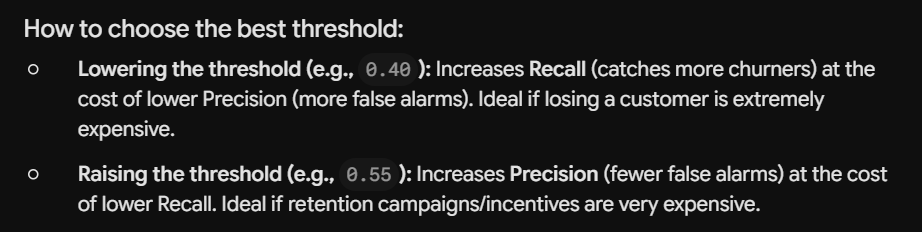

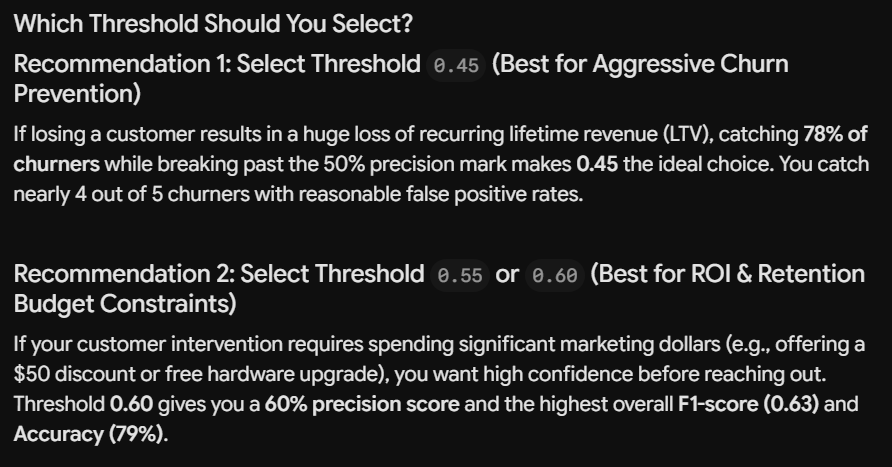

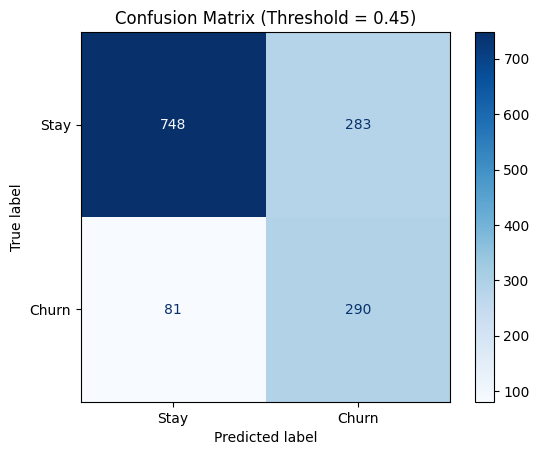

In [ ]:
# Set your chosen business threshold
OPTIMAL_THRESHOLD = 0.45

# Calculate predictions based on probabilities
y_prob = best_pipeline.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob >= OPTIMAL_THRESHOLD).astype(int)

# Verify confusion matrix at this threshold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stay', 'Churn'])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix (Threshold = {OPTIMAL_THRESHOLD})')
plt.show()

In [ ]:
# Final predictions with optimal threshold
optimal_thresh = 0.45
y_final_pred = (y_probs >= optimal_thresh).astype(int)

# Extract tuned model coefficients
final_model = best_pipeline.named_steps['classifier']
feature_names = X.columns

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': final_model.coef_[0],
    'Odds_Ratio': np.exp(final_model.coef_[0])  # Scale multiplier
}).sort_values(by='Coefficient', ascending=False)

print("--- Top Churn Drivers ---")
print(feature_importance.head(5))

print("\n--- Top Retention Drivers ---")
print(feature_importance.tail(5))

--- Top Churn Drivers ---
                           Feature  Coefficient  Odds_Ratio
1                   MonthlyCharges     0.693737    2.001180
5   MultipleLines_No phone service     0.359189    1.432167
7      InternetService_Fiber optic     0.326446    1.386033
17            PaperlessBilling_Yes     0.178853    1.195845
19  PaymentMethod_Electronic check     0.158599    1.171868

--- Top Retention Drivers ---
               Feature  Coefficient  Odds_Ratio
15   Contract_One year    -0.495299    0.609389
12     TechSupport_Yes    -0.516040    0.596880
0               tenure    -0.520488    0.594231
9   OnlineSecurity_Yes    -0.544248    0.580278
16   Contract_Two year    -0.734939    0.479535


### Deep Learning

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report

# 1. Build the Neural Network Architecture
model = Sequential([
    # Input Layer + First Hidden Layer
    Dense(64, activation='relu', input_shape=(X_train_smote.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),

    # Second Hidden Layer
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    # Output Layer for Binary Classification
    Dense(1, activation='sigmoid')
])

# 2. Compile the Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy', # Standard loss for binary churn prediction
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

# 3. Add Early Stopping to stop training when validation performance stalls
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# 4. Train the Model
history = model.fit(
    X_train_smote, y_train_smote,
    epochs=100,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 5. Evaluate on the untouched Scaled Test Set at your chosen Threshold (e.g., 0.45)
THRESHOLD = 0.45
dl_probs = model.predict(X_test)
dl_preds = (dl_probs >= THRESHOLD).astype(int)

print("\n--- Deep Learning Classification Report ---")
print(classification_report(y_test, dl_preds))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6999 - loss: 0.6036 - recall: 0.6830 - val_accuracy: 0.3845 - val_loss: 0.8119 - val_recall: 0.3845
Epoch 2/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7527 - loss: 0.5117 - recall: 0.6717 - val_accuracy: 0.5646 - val_loss: 0.7470 - val_recall: 0.5646
Epoch 3/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7588 - loss: 0.4989 - recall: 0.6733 - val_accuracy: 0.6737 - val_loss: 0.6573 - val_recall: 0.6737
Epoch 4/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7625 - loss: 0.4829 - recall: 0.6700 - val_accuracy: 0.7392 - val_loss: 0.5651 - val_recall: 0.7392
Epoch 5/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7680 - loss: 0.4804 - recall: 0.6793 - val_accuracy: 0.7586 - val_loss: 0.5275 - val_recall: 0.7586
Epoch 6/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7641 - loss: 0.4721 - recall: 0.6773 - val_accuracy: 0.7617 - val_loss: 0.5548 - val_recall: 0.761

### **Feature Summary after best trained MODEL**

In [ ]:
import pandas as pd
import numpy as np

# Extract final classifier from your pipeline
final_model = best_pipeline.named_steps['classifier']

# Build feature importance table
feature_summary = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_model.coef_[0],
    'Odds_Ratio': np.exp(final_model.coef_[0])
}).sort_values(by='Coefficient', ascending=False)

# Interpretation:
# Odds Ratio > 1: Increases churn risk (e.g., Month-to-Month contracts)
# Odds Ratio < 1: Protects against churn (e.g., Long tenure, 2-Year contracts)
print(feature_summary)

                                  Feature  Coefficient  Odds_Ratio
1                          MonthlyCharges     0.693737    2.001180
5          MultipleLines_No phone service     0.359189    1.432167
7             InternetService_Fiber optic     0.326446    1.386033
17                   PaperlessBilling_Yes     0.178853    1.195845
19         PaymentMethod_Electronic check     0.158599    1.171868
2                           SeniorCitizen     0.049980    1.051250
14                    StreamingMovies_Yes     0.035141    1.035765
13                        StreamingTV_Yes     0.012560    1.012639
6                       MultipleLines_Yes     0.002875    1.002879
3                             Partner_Yes    -0.189799    0.827125
21                        TotalCharges_yj    -0.212784    0.808331
10                       OnlineBackup_Yes    -0.225572    0.798060
20             PaymentMethod_Mailed check    -0.246014    0.781911
11                   DeviceProtection_Yes    -0.269803    0.76

### Saving the ENTIRE PIPELINE

In [ ]:
import joblib

# Save the trained pipeline to disk
joblib.dump(best_pipeline, 'churn_logistic_pipeline.pkl')

# Test loading the pipeline
loaded_pipeline = joblib.load('churn_logistic_pipeline.pkl')
# Direct prediction on raw test input
sample_predictions = loaded_pipeline.predict(X_test)

In [ ]:
sample_predictions

array([1, 0, 0, ..., 0, 0, 0])